# RQ III: Agent ablations


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "reported_runs/analysis").is_dir())
sys.path.insert(0, str(repo)) if str(repo) not in sys.path else None
from reported_runs.analysis.presentation import load_results, NotebookReport, temporal_table, effect_table, rank_summary, unique_trajectories, label_conditions
from reported_runs.analysis.plotting import trajectory_grid, effect_grid, rank_grid, association_grid
from reported_runs.analysis.comparisons import summarise_iterations
%matplotlib inline

results = load_results()
report = NotebookReport(results, 'rq3')
scales = report.scales
trajectory = label_conditions(results["trajectory"])
sources = results["sources"]
summaries = results["summaries"]
effect_summaries = results["effect_summaries"]
pd.set_option("display.max_columns", 18)
pd.set_option("display.max_rows", 60)

## Sequential agent ablations


In [2]:
from reported_runs.analysis.sections_rq1_3 import diagnostic_tables, horizon_counts, reflection_totals, arm_rank_statistics, profile_review_details
from reported_runs.analysis.agent_ablation_views import ABLATION_COMPARISON_ORDER, label_ablation_comparisons, ablation_effect_ranges
agents = trajectory.loc[trajectory.study.eq('movielens_feedback_a300_e804') & trajectory.model.eq('agentic_recommender') & trajectory.stage.str.startswith(('L2', 'L3'))].copy()
ablations = label_ablation_comparisons(effect_summaries.loc[effect_summaries.study.eq('movielens_feedback_a300_e804') & effect_summaries.kind.eq('ablation')])
report.table(label_ablation_comparisons(results['comparison_plan'].loc[results['comparison_plan'].kind.eq('ablation')]), 'rq3_ablation_controls', "")

,dataset,study,seed,population_seed,comparison,kind,rqs,model,stage,mitigation,treatment_condition,control_condition,treatment_physical_run_id,control_physical_run_id,eligible,pair_status,ablation_order
0,movielens,movielens_feedback_a300_e804,42,1054,Decision-input noise check: no reflection minu...,ablation,III,agentic_recommender,L3_individual,none,L3_individual__agentic_recommender__sasrec__no...,L2_ml_model__agentic_recommender__sasrec__orde...,feedback_new_sampling_p1054_a300_r0_e804__L3_i...,feedback_new_sampling_p1054_a300_r0_e804__L2_m...,True,complete,0
1,movielens,movielens_feedback_a300_e804,42,1054,Reflection notes: fixed profile minus no refle...,ablation,III,agentic_recommender,L3_individual,none,L3_individual__agentic_recommender__sasrec__fi...,L3_individual__agentic_recommender__sasrec__no...,feedback_new_sampling_p1054_a300_r0_e804__L3_i...,feedback_new_sampling_p1054_a300_r0_e804__L3_i...,True,complete,1
2,movielens,movielens_feedback_a300_e804,42,1054,Profile updates: full reflection minus fixed p...,ablation,III,agentic_recommender,L3_individual,none,L3_individual__agentic_recommender__sasrec__fu...,L3_individual__agentic_recommender__sasrec__fi...,mitigation_v1_primary_p1054_a300_r0__agentic_r...,feedback_new_sampling_p1054_a300_r0_e804__L3_i...,True,complete,2
3,movielens,movielens_feedback_a300_e804,43,19277,Decision-input noise check: no reflection minu...,ablation,III,agentic_recommender,L3_individual,none,L3_individual__agentic_recommender__sasrec__no...,L2_ml_model__agentic_recommender__sasrec__orde...,feedback_new_sampling_p19277_a300_r0_e804__L3_...,feedback_new_sampling_p19277_a300_r0_e804__L2_...,True,complete,0
4,movielens,movielens_feedback_a300_e804,43,19277,Reflection notes: fixed profile minus no refle...,ablation,III,agentic_recommender,L3_individual,none,L3_individual__agentic_recommender__sasrec__fi...,L3_individual__agentic_recommender__sasrec__no...,feedback_new_sampling_p19277_a300_r0_e804__L3_...,feedback_new_sampling_p19277_a300_r0_e804__L3_...,True,complete,1
5,movielens,movielens_feedback_a300_e804,43,19277,Profile updates: full reflection minus fixed p...,ablation,III,agentic_recommender,L3_individual,none,L3_individual__agentic_recommender__sasrec__fu...,L3_individual__agentic_recommender__sasrec__fi...,mitigation_v1_primary_p19277_a300_r0__agentic_...,feedback_new_sampling_p19277_a300_r0_e804__L3_...,True,complete,2
6,movielens,movielens_feedback_a300_e804,44,18844,Decision-input noise check: no reflection minu...,ablation,III,agentic_recommender,L3_individual,none,L3_individual__agentic_recommender__sasrec__no...,L2_ml_model__agentic_recommender__sasrec__orde...,feedback_new_sampling_p18844_a300_r0_e804__L3_...,feedback_new_sampling_p18844_a300_r0_e804__L2_...,True,complete,0
7,movielens,movielens_feedback_a300_e804,44,18844,Reflection notes: fixed profile minus no refle...,ablation,III,agentic_recommender,L3_individual,none,L3_individual__agentic_recommender__sasrec__fi...,L3_individual__agentic_recommender__sasrec__no...,feedback_new_sampling_p18844_a300_r0_e804__L3_...,feedback_new_sampling_p18844_a300_r0_e804__L3_...,True,complete,1
8,movielens,movielens_feedback_a300_e804,44,18844,Profile updates: full reflection minus fixed p...,ablation,III,agentic_recommender,L3_individual,none,L3_individual__agentic_recommender__sasrec__fu...,L3_individual__agentic_recommender__sasrec__fi...,feedback_new_sampling_p18844_a300_r0_e804__L3_...,feedback_new_sampling_p18844_a300_r0_e804__L3_...,True,complete,2


LaTeX label: `chap:results:tab:rq3_ablation_controls` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_ablation_controls.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_ablation_controls.csv)

## Recorded memory use and forced actions


In [3]:
from reported_runs.analysis.agent_usage import load_agent_usage
from reported_runs.analysis.sections_rq1_3 import agent_usage_summary
usage_sources = sources.loc[sources.model.eq('agentic_recommender') & ((sources.study.eq('movielens_feedback_a300_e804') & sources.stage.str.startswith(('L2', 'L3'))) | sources.study.eq('movielens_sampling_outcome_a150_r150_e804'))]
usage = load_agent_usage(usage_sources, repo, repo / 'reported_runs/analysis/cache/agent_usage')
canonical_usage = usage.loc[usage.arm.eq('canonical')]
usage_columns = ['Protocol', 'Presentation arm', 'Runs', 'Decisions', 'Memory calls', 'Forced actions']
report.table(agent_usage_summary(canonical_usage), 'rq3_memory_forced_action_summary', "", columns=usage_columns, source_frame=canonical_usage)
report.table(agent_usage_summary(canonical_usage, by_condition=True), 'rq3_memory_forced_actions_by_condition', "", columns=['Protocol', 'Seed', 'Condition', 'Decisions', 'Memory calls', 'Forced actions'], source_frame=canonical_usage)
probe_usage = usage.loc[usage.arm.ne('canonical')]
report.table(agent_usage_summary(probe_usage), 'rq3_probe_memory_forced_actions', "", columns=usage_columns, source_frame=probe_usage)

,Protocol,Presentation arm,Runs,Decisions,Memory calls,Forced actions
0,RQ III: 300 active users (L2/L3),canonical,12,108000,0,0
1,150 active / 150 reserve protocol,canonical,21,89177,2,0


LaTeX label: `chap:results:tab:rq3_memory_forced_action_summary` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_memory_forced_action_summary.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_memory_forced_action_summary.csv)

,Protocol,Seed,Condition,Decisions,Memory calls,Forced actions
0,RQ III: 300 active users (L2/L3),42,L2 -- frozen agent,9000,0,0
1,RQ III: 300 active users (L2/L3),42,L3 -- fixed profile,9000,0,0
2,RQ III: 300 active users (L2/L3),42,L3 -- full reflection,9000,0,0
3,RQ III: 300 active users (L2/L3),42,L3 -- no reflection,9000,0,0
4,RQ III: 300 active users (L2/L3),43,L2 -- frozen agent,9000,0,0
5,RQ III: 300 active users (L2/L3),43,L3 -- fixed profile,9000,0,0
6,RQ III: 300 active users (L2/L3),43,L3 -- full reflection,9000,0,0
7,RQ III: 300 active users (L2/L3),43,L3 -- no reflection,9000,0,0
8,RQ III: 300 active users (L2/L3),44,L2 -- frozen agent,9000,0,0
9,RQ III: 300 active users (L2/L3),44,L3 -- fixed profile,9000,0,0


LaTeX label: `chap:results:tab:rq3_memory_forced_actions_by_condition` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_memory_forced_actions_by_condition.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_memory_forced_actions_by_condition.csv)

,Protocol,Presentation arm,Runs,Decisions,Memory calls,Forced actions
0,RQ III: 300 active users (L2/L3),replica,12,108000,1,0
1,RQ III: 300 active users (L2/L3),shuffled,12,108000,1,0


LaTeX label: `chap:results:tab:rq3_probe_memory_forced_actions` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_probe_memory_forced_actions.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_probe_memory_forced_actions.csv)

## Bias trajectories and successive configuration effects


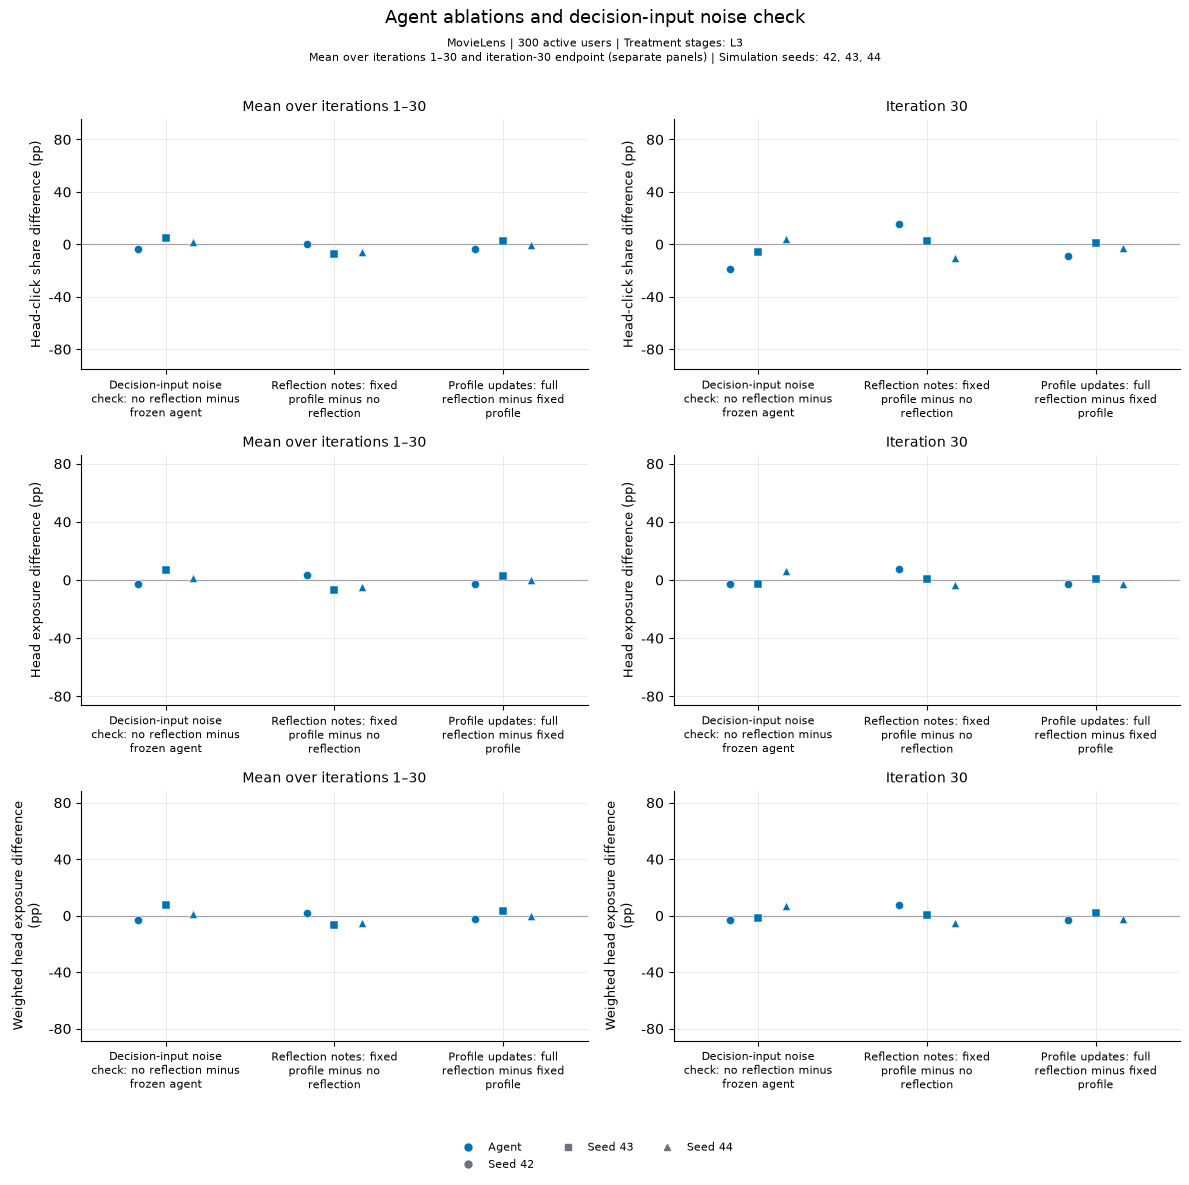

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_ablation_effects.pdf) · [PNG](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_ablation_effects.png) · label `chap:results:fig:rq3_ablation_effects`

,comparison,metric,window,n_seed_blocks,min_effect,max_effect,reference_min,reference_max
0,Decision-input noise check: no reflection minu...,head_click_share,iteration_30,3,-19.0325,3.90071,-19.0325,3.90071
1,Reflection notes: fixed profile minus no refle...,head_click_share,iteration_30,3,-10.1239,15.537,-19.0325,3.90071
2,Profile updates: full reflection minus fixed p...,head_click_share,iteration_30,3,-9.21833,1.02309,-19.0325,3.90071
3,Decision-input noise check: no reflection minu...,head_click_share,mean_1_30,3,-3.92734,4.47714,-3.92734,4.47714
4,Reflection notes: fixed profile minus no refle...,head_click_share,mean_1_30,3,-7.53558,-0.0732353,-3.92734,4.47714
5,Profile updates: full reflection minus fixed p...,head_click_share,mean_1_30,3,-3.46881,2.835,-3.92734,4.47714
6,Decision-input noise check: no reflection minu...,head_exposure,iteration_30,3,-2.93333,6.53333,-2.93333,6.53333
7,Reflection notes: fixed profile minus no refle...,head_exposure,iteration_30,3,-3.6,7.36667,-2.93333,6.53333
8,Profile updates: full reflection minus fixed p...,head_exposure,iteration_30,3,-3,0.6,-2.93333,6.53333
9,Decision-input noise check: no reflection minu...,head_exposure,mean_1_30,3,-2.77889,6.63111,-2.77889,6.63111


LaTeX label: `chap:results:tab:rq3_effect_ranges_and_noise_reference` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_effect_ranges_and_noise_reference.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_effect_ranges_and_noise_reference.csv)

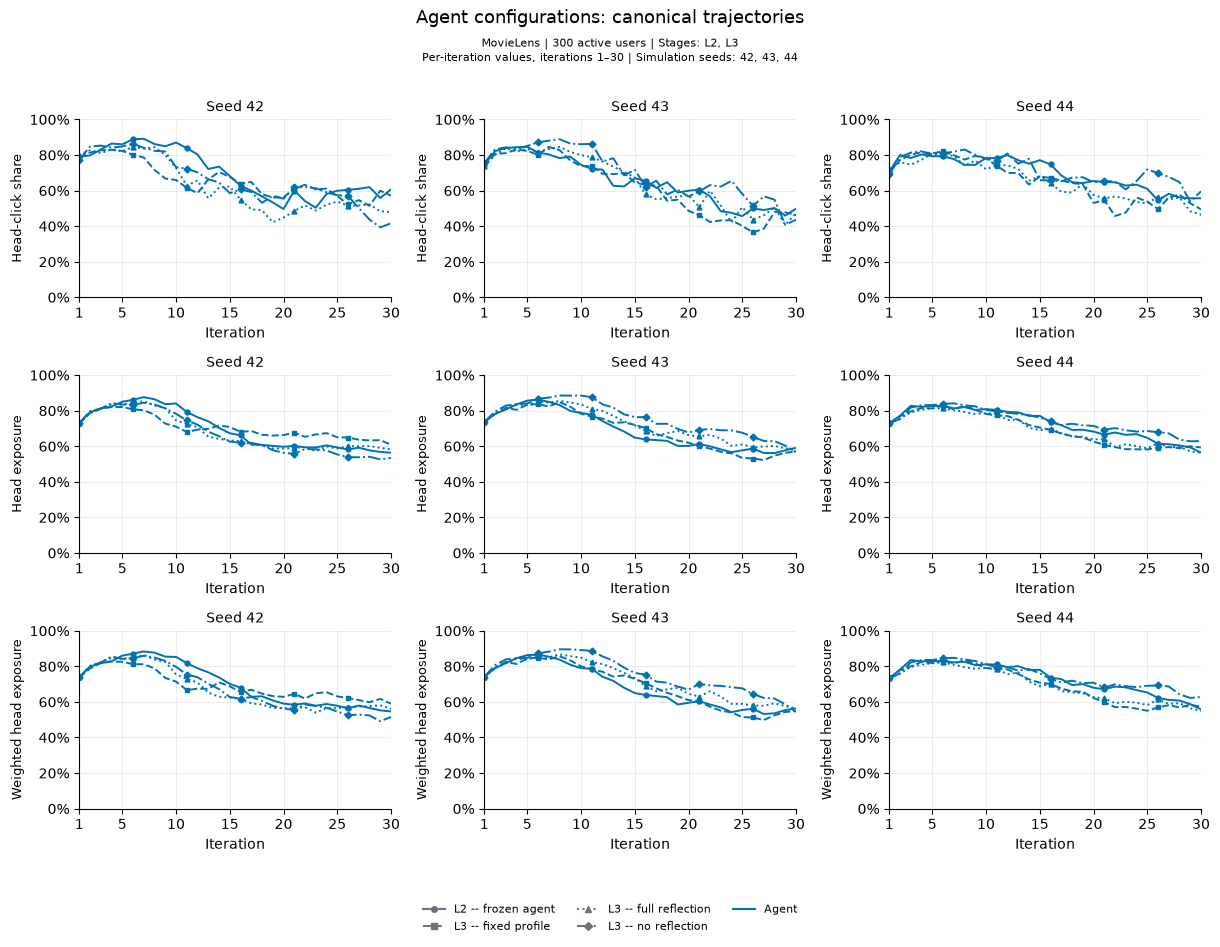

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_agent_trajectories.pdf) · [PNG](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_agent_trajectories.png) · label `chap:results:fig:rq3_agent_trajectories`

,Model,Seed,Time summary,Head-click share,Head exposure,Weighted head exposure,Condition
0,Agent,42,iteration_30,0.606383,0.564,0.546514,L2 -- frozen agent
1,Agent,42,mean_1_30,0.697789,0.697011,0.702201,L2 -- frozen agent
2,Agent,43,iteration_30,0.498221,0.591333,0.563339,L2 -- frozen agent
3,Agent,43,mean_1_30,0.651245,0.687822,0.682495,L2 -- frozen agent
4,Agent,44,iteration_30,0.556738,0.564,0.558615,L2 -- frozen agent
5,Agent,44,mean_1_30,0.698312,0.727078,0.731998,L2 -- frozen agent
6,Agent,42,iteration_30,0.479245,0.582,0.561951,L3 -- full reflection
7,Agent,42,mean_1_30,0.623095,0.679633,0.670666,L3 -- full reflection
8,Agent,43,iteration_30,0.472325,0.576667,0.564101,L3 -- full reflection
9,Agent,43,mean_1_30,0.64901,0.719011,0.719238,L3 -- full reflection


LaTeX label: `chap:results:tab:rq3_agents_head_outcomes` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_head_outcomes.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_head_outcomes.csv)

,Model,Seed,Time summary,Click-exposure gap (unweighted exposure) (pp),Click-exposure gap (rank-weighted exposure) (pp),Condition
0,Agent,42,iteration_30,4.2383,5.98686,L2 -- frozen agent
1,Agent,42,mean_1_30,0.0778177,-0.441187,L2 -- frozen agent
2,Agent,43,iteration_30,-9.31127,-6.51187,L2 -- frozen agent
3,Agent,43,mean_1_30,-3.65774,-3.125,L2 -- frozen agent
4,Agent,44,iteration_30,-0.726241,-0.187737,L2 -- frozen agent
5,Agent,44,mean_1_30,-2.87656,-3.36861,L2 -- frozen agent
6,Agent,42,iteration_30,-10.2755,-8.2706,L3 -- full reflection
7,Agent,42,mean_1_30,-5.6538,-4.75708,L3 -- full reflection
8,Agent,43,iteration_30,-10.4342,-9.17761,L3 -- full reflection
9,Agent,43,mean_1_30,-7.00006,-7.02279,L3 -- full reflection


LaTeX label: `chap:results:tab:rq3_agents_selection` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_selection.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_selection.csv)

In [4]:
figure = effect_grid(ablations, ['head_click_share', 'head_exposure', 'weighted_head_exposure'], title='Agent ablations and decision-input noise check', scales=scales, value='value', facet='window', category_order=ABLATION_COMPARISON_ORDER)
report.figure(figure, ablations, 'rq3_ablation_effects', "", recommended=False, why="")
effect_ranges = ablation_effect_ranges(ablations, ['head_click_share', 'head_exposure', 'weighted_head_exposure'])
report.table(effect_ranges, 'rq3_effect_ranges_and_noise_reference', "", columns=['comparison', 'metric', 'window', 'n_seed_blocks', 'min_effect', 'max_effect', 'reference_min', 'reference_max'], source_frame=ablations)
figure = trajectory_grid(agents, ['head_click_share', 'head_exposure', 'weighted_head_exposure'], title='Agent configurations: canonical trajectories', scales=scales, series='condition_label')
report.figure(figure, agents, 'rq3_agent_trajectories', "")
diagnostic_tables(report, agents, {'head_outcomes': ['head_click_share', 'head_exposure', 'weighted_head_exposure'], 'selection': ['click_exposure_gap', 'weighted_click_exposure_gap']}, prefix='rq3_agents', context="")

## Click behaviour, coverage, and repeated responses


In [5]:
diagnostic_tables(report, agents, {'click_behaviour': ['click_rate', 'no_click_rate', 'invalid_rate', 'valid_clicks'], 'coverage': ['exposure_coverage', 'click_coverage'], 'concentration': ['exposure_gini', 'click_gini'], 'rank_statistics': ['mean_clicked_rank', 'first_position_click_share']}, prefix='rq3_agents', context="")
agent_probes = label_conditions(results['probes'].loc[results['probes'].study.eq('movielens_feedback_a300_e804') & results['probes'].model.eq('agentic_recommender') & results['probes'].stage.str.startswith(('L2', 'L3'))])
diagnostic_tables(report, agent_probes, {'agreement': ['replica_agreement', 'shuffled_agreement', 'agreement_sensitivity'], 'actions': ['replica_action_agreement', 'replica_action_disagreement', 'shuffled_action_agreement', 'shuffled_action_disagreement'], 'eligibility': ['triple_valid_clicks', 'replica_valid_pairs', 'shuffled_valid_pairs'], 'excluded_pairs': ['replica_excluded_non_valid_pairs', 'shuffled_excluded_non_valid_pairs']}, prefix='rq3_agents', context="")

,Model,Seed,Time summary,Click rate,Invalid-response rate,No-click rate,Valid click counts,Condition
0,Agent,42,iteration_30,0.94,0,0.06,282,L2 -- frozen agent
1,Agent,42,mean_1_30,0.937333,0,0.0626667,281.2,L2 -- frozen agent
2,Agent,43,iteration_30,0.936667,0,0.0633333,281,L2 -- frozen agent
3,Agent,43,mean_1_30,0.934556,0,0.0654444,280.367,L2 -- frozen agent
4,Agent,44,iteration_30,0.94,0,0.06,282,L2 -- frozen agent
5,Agent,44,mean_1_30,0.945,0,0.055,283.5,L2 -- frozen agent
6,Agent,42,iteration_30,0.883333,0,0.116667,265,L3 -- full reflection
7,Agent,42,mean_1_30,0.925222,0,0.0747778,277.567,L3 -- full reflection
8,Agent,43,iteration_30,0.903333,0,0.0966667,271,L3 -- full reflection
9,Agent,43,mean_1_30,0.922222,0,0.0777778,276.667,L3 -- full reflection


LaTeX label: `chap:results:tab:rq3_agents_click_behaviour` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_click_behaviour.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_click_behaviour.csv)

,Model,Seed,Time summary,Catalogue coverage (clicks),Catalogue coverage (exposure),Condition
0,Agent,42,iteration_30,0.0313232,0.127342,L2 -- frozen agent
1,Agent,42,mean_1_30,0.0324746,0.144331,L2 -- frozen agent
2,Agent,43,iteration_30,0.030445,0.117096,L2 -- frozen agent
3,Agent,43,mean_1_30,0.0331382,0.143648,L2 -- frozen agent
4,Agent,44,iteration_30,0.0322014,0.117389,L2 -- frozen agent
5,Agent,44,mean_1_30,0.0349922,0.148019,L2 -- frozen agent
6,Agent,42,iteration_30,0.0301522,0.124122,L3 -- full reflection
7,Agent,42,mean_1_30,0.0340847,0.145121,L3 -- full reflection
8,Agent,43,iteration_30,0.0307377,0.115047,L3 -- full reflection
9,Agent,43,mean_1_30,0.0353825,0.149356,L3 -- full reflection


LaTeX label: `chap:results:tab:rq3_agents_coverage` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_coverage.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_coverage.csv)

,Model,Seed,Time summary,Gini (clicks),Gini (exposure),Condition
0,Agent,42,iteration_30,0.983643,0.966977,L2 -- frozen agent
1,Agent,42,mean_1_30,0.982858,0.954094,L2 -- frozen agent
2,Agent,43,iteration_30,0.985019,0.971438,L2 -- frozen agent
3,Agent,43,mean_1_30,0.982017,0.952013,L2 -- frozen agent
4,Agent,44,iteration_30,0.983839,0.967644,L2 -- frozen agent
5,Agent,44,mean_1_30,0.980612,0.949177,L2 -- frozen agent
6,Agent,42,iteration_30,0.984702,0.966606,L3 -- full reflection
7,Agent,42,mean_1_30,0.981484,0.952007,L3 -- full reflection
8,Agent,43,iteration_30,0.983675,0.969322,L3 -- full reflection
9,Agent,43,mean_1_30,0.980004,0.947336,L3 -- full reflection


LaTeX label: `chap:results:tab:rq3_agents_concentration` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_concentration.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_concentration.csv)

... (6 outputs left out)

,Model,Seed,Time summary,Replica valid pairs,Shuffled valid pairs,Triple valid clicks,Condition
0,Agent,42,iteration_30,300,300,247,L2 -- frozen agent
1,Agent,42,mean_1_30,300,300,256.467,L2 -- frozen agent
2,Agent,43,iteration_30,300,300,253,L2 -- frozen agent
3,Agent,43,mean_1_30,300,300,257.767,L2 -- frozen agent
4,Agent,44,iteration_30,300,300,257,L2 -- frozen agent
5,Agent,44,mean_1_30,300,300,259.933,L2 -- frozen agent
6,Agent,42,iteration_30,300,300,236,L3 -- full reflection
7,Agent,42,mean_1_30,300,300,255.333,L3 -- full reflection
8,Agent,43,iteration_30,300,300,253,L3 -- full reflection
9,Agent,43,mean_1_30,300,300,252.067,L3 -- full reflection


LaTeX label: `chap:results:tab:rq3_agents_eligibility` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_eligibility.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_eligibility.csv)

,Model,Seed,Time summary,Replica excluded non valid pairs,Shuffled excluded non valid pairs,Condition
0,Agent,42,iteration_30,0,0,L2 -- frozen agent
1,Agent,42,mean_1_30,0,0,L2 -- frozen agent
2,Agent,43,iteration_30,0,0,L2 -- frozen agent
3,Agent,43,mean_1_30,0,0,L2 -- frozen agent
4,Agent,44,iteration_30,0,0,L2 -- frozen agent
5,Agent,44,mean_1_30,0,0,L2 -- frozen agent
6,Agent,42,iteration_30,0,0,L3 -- full reflection
7,Agent,42,mean_1_30,0,0,L3 -- full reflection
8,Agent,43,iteration_30,0,0,L3 -- full reflection
9,Agent,43,mean_1_30,0,0,L3 -- full reflection


LaTeX label: `chap:results:tab:rq3_agents_excluded_pairs` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_excluded_pairs.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_excluded_pairs.csv)

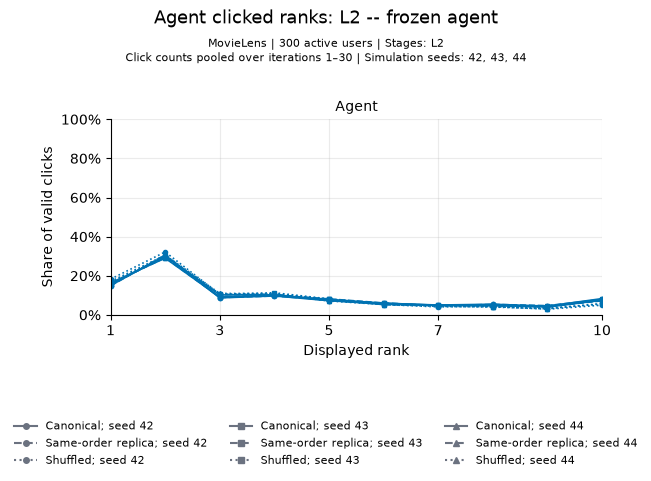

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_ranks_l2_ml_model_agentic_recommender_sasrec_order_probe.pdf) · [PNG](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_ranks_l2_ml_model_agentic_recommender_sasrec_order_probe.png) · label `chap:results:fig:rq3_ranks_l2_ml_model_agentic_recommender_sasrec_order_probe`

,dataset,study,condition_id,model,stage,seed,population_seed,arm,rank,clicks,click_share
0,movielens,movielens_feedback_a300_e804,L2_ml_model__agentic_recommender__sasrec__orde...,agentic_recommender,L2_ml_model,42,1054,canonical,1,1266,0.150071
1,movielens,movielens_feedback_a300_e804,L2_ml_model__agentic_recommender__sasrec__orde...,agentic_recommender,L2_ml_model,42,1054,canonical,2,2545,0.301683
2,movielens,movielens_feedback_a300_e804,L2_ml_model__agentic_recommender__sasrec__orde...,agentic_recommender,L2_ml_model,42,1054,canonical,3,733,0.0868895
3,movielens,movielens_feedback_a300_e804,L2_ml_model__agentic_recommender__sasrec__orde...,agentic_recommender,L2_ml_model,42,1054,canonical,4,817,0.0968468
4,movielens,movielens_feedback_a300_e804,L2_ml_model__agentic_recommender__sasrec__orde...,agentic_recommender,L2_ml_model,42,1054,canonical,5,612,0.0725462
...,...,...,...,...,...,...,...,...,...,...,...
85,movielens,movielens_feedback_a300_e804,L2_ml_model__agentic_recommender__sasrec__orde...,agentic_recommender,L2_ml_model,44,18844,shuffled,6,453,0.0533192
86,movielens,movielens_feedback_a300_e804,L2_ml_model__agentic_recommender__sasrec__orde...,agentic_recommender,L2_ml_model,44,18844,shuffled,7,370,0.0435499
87,movielens,movielens_feedback_a300_e804,L2_ml_model__agentic_recommender__sasrec__orde...,agentic_recommender,L2_ml_model,44,18844,shuffled,8,341,0.0401365
88,movielens,movielens_feedback_a300_e804,L2_ml_model__agentic_recommender__sasrec__orde...,agentic_recommender,L2_ml_model,44,18844,shuffled,9,264,0.0310734


LaTeX label: `chap:results:tab:rq3_rank_counts_l2_ml_model_agentic_recommender_sasrec_order_probe` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_rank_counts_l2_ml_model_agentic_recommender_sasrec_order_probe.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_rank_counts_l2_ml_model_agentic_recommender_sasrec_order_probe.csv)

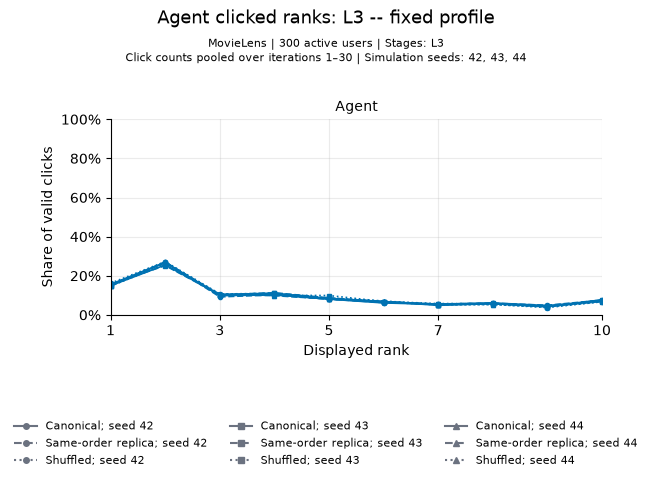

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_ranks_l3_individual_agentic_recommender_sasrec_fixed_persona_memory_only_order_probe.pdf) · [PNG](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_ranks_l3_individual_agentic_recommender_sasrec_fixed_persona_memory_only_order_probe.png) · label `chap:results:fig:rq3_ranks_l3_individual_agentic_recommender_sasrec_fixed_persona_memory_only_order_probe`

,dataset,study,condition_id,model,stage,seed,population_seed,arm,rank,clicks,click_share
0,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fi...,agentic_recommender,L3_individual,42,1054,canonical,1,1296,0.155713
1,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fi...,agentic_recommender,L3_individual,42,1054,canonical,2,2240,0.269134
2,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fi...,agentic_recommender,L3_individual,42,1054,canonical,3,817,0.0981617
3,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fi...,agentic_recommender,L3_individual,42,1054,canonical,4,851,0.102247
4,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fi...,agentic_recommender,L3_individual,42,1054,canonical,5,669,0.0803797
...,...,...,...,...,...,...,...,...,...,...,...
85,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fi...,agentic_recommender,L3_individual,44,18844,shuffled,6,599,0.0711909
86,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fi...,agentic_recommender,L3_individual,44,18844,shuffled,7,435,0.0516995
87,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fi...,agentic_recommender,L3_individual,44,18844,shuffled,8,442,0.0525315
88,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fi...,agentic_recommender,L3_individual,44,18844,shuffled,9,340,0.0404088


LaTeX label: `chap:results:tab:rq3_rank_counts_l3_individual_agentic_recommender_sasrec_fixed_persona_memory_only_order_probe` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_rank_counts_l3_individual_agentic_recommender_sasrec_fixed_persona_memory_only_order_probe.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_rank_counts_l3_individual_agentic_recommender_sasrec_fixed_persona_memory_only_order_probe.csv)

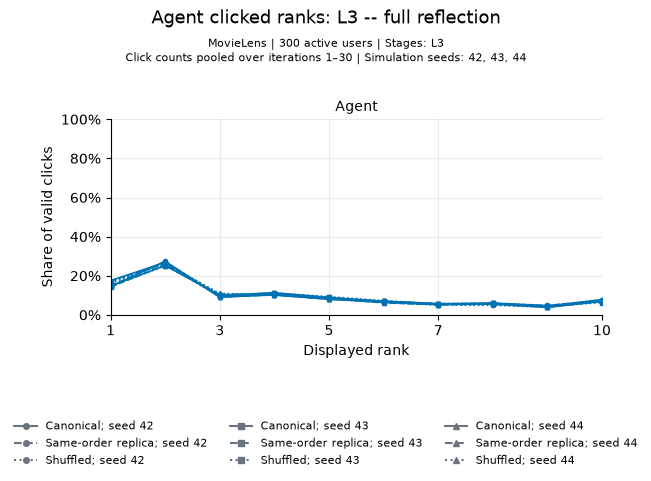

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_ranks_l3_individual_agentic_recommender_sasrec_full_reflection_order_probe.pdf) · [PNG](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_ranks_l3_individual_agentic_recommender_sasrec_full_reflection_order_probe.png) · label `chap:results:fig:rq3_ranks_l3_individual_agentic_recommender_sasrec_full_reflection_order_probe`

,dataset,study,condition_id,model,stage,seed,population_seed,arm,rank,clicks,click_share
0,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fu...,agentic_recommender,L3_individual,42,1054,canonical,1,1198,0.143869
1,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fu...,agentic_recommender,L3_individual,42,1054,canonical,2,2282,0.274048
2,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fu...,agentic_recommender,L3_individual,42,1054,canonical,3,746,0.0895881
3,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fu...,agentic_recommender,L3_individual,42,1054,canonical,4,867,0.104119
4,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fu...,agentic_recommender,L3_individual,42,1054,canonical,5,676,0.0811817
...,...,...,...,...,...,...,...,...,...,...,...
85,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fu...,agentic_recommender,L3_individual,44,18844,shuffled,6,534,0.0634129
86,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fu...,agentic_recommender,L3_individual,44,18844,shuffled,7,451,0.0535566
87,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fu...,agentic_recommender,L3_individual,44,18844,shuffled,8,474,0.0562879
88,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__fu...,agentic_recommender,L3_individual,44,18844,shuffled,9,348,0.0413253


LaTeX label: `chap:results:tab:rq3_rank_counts_l3_individual_agentic_recommender_sasrec_full_reflection_order_probe` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_rank_counts_l3_individual_agentic_recommender_sasrec_full_reflection_order_probe.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_rank_counts_l3_individual_agentic_recommender_sasrec_full_reflection_order_probe.csv)

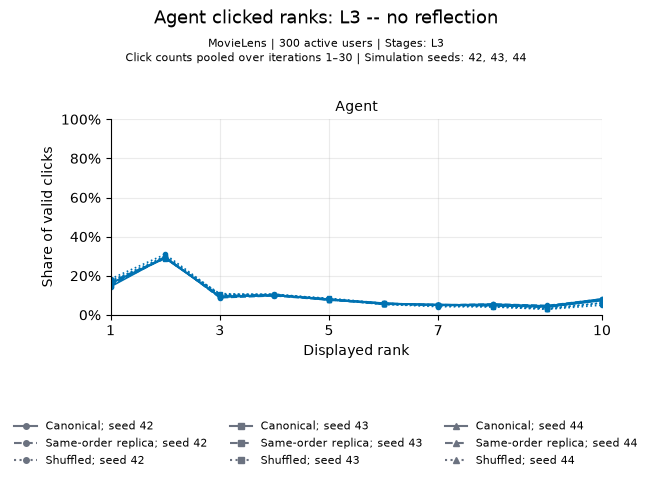

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_ranks_l3_individual_agentic_recommender_sasrec_no_reflection_control_order_probe.pdf) · [PNG](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_ranks_l3_individual_agentic_recommender_sasrec_no_reflection_control_order_probe.png) · label `chap:results:fig:rq3_ranks_l3_individual_agentic_recommender_sasrec_no_reflection_control_order_probe`

,dataset,study,condition_id,model,stage,seed,population_seed,arm,rank,clicks,click_share
0,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__no...,agentic_recommender,L3_individual,42,1054,canonical,1,1213,0.144113
1,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__no...,agentic_recommender,L3_individual,42,1054,canonical,2,2480,0.294642
2,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__no...,agentic_recommender,L3_individual,42,1054,canonical,3,765,0.0908875
3,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__no...,agentic_recommender,L3_individual,42,1054,canonical,4,846,0.100511
4,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__no...,agentic_recommender,L3_individual,42,1054,canonical,5,667,0.0792444
...,...,...,...,...,...,...,...,...,...,...,...
85,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__no...,agentic_recommender,L3_individual,44,18844,shuffled,6,449,0.0531047
86,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__no...,agentic_recommender,L3_individual,44,18844,shuffled,7,398,0.0470727
87,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__no...,agentic_recommender,L3_individual,44,18844,shuffled,8,381,0.0450621
88,movielens,movielens_feedback_a300_e804,L3_individual__agentic_recommender__sasrec__no...,agentic_recommender,L3_individual,44,18844,shuffled,9,275,0.0325251


LaTeX label: `chap:results:tab:rq3_rank_counts_l3_individual_agentic_recommender_sasrec_no_reflection_control_order_probe` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_rank_counts_l3_individual_agentic_recommender_sasrec_no_reflection_control_order_probe.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_rank_counts_l3_individual_agentic_recommender_sasrec_no_reflection_control_order_probe.csv)

,Model,Seed,arm,Time summary,First-position click share,Mean clicked rank,Condition
0,Agent,42,canonical,iteration_30,0.141844,4.85816,L2 -- frozen agent
1,Agent,42,canonical,mean_1_30,0.149976,4.14258,L2 -- frozen agent
2,Agent,42,replica,iteration_30,0.177536,3.80435,L2 -- frozen agent
3,Agent,42,replica,mean_1_30,0.148202,4.10703,L2 -- frozen agent
4,Agent,42,shuffled,iteration_30,0.186131,3.4854,L2 -- frozen agent
...,...,...,...,...,...,...,...
67,Agent,44,canonical,mean_1_30,0.159111,4.04824,L3 -- no reflection
68,Agent,44,replica,iteration_30,0.139194,4.06227,L3 -- no reflection
69,Agent,44,replica,mean_1_30,0.150365,4.09983,L3 -- no reflection
70,Agent,44,shuffled,iteration_30,0.194946,3.63899,L3 -- no reflection


LaTeX label: `chap:results:tab:rq3_agents_rank_statistics_by_arm` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_rank_statistics_by_arm.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_rank_statistics_by_arm.csv)

In [6]:
agent_ranks = results['ranks'].loc[results['ranks'].study.eq('movielens_feedback_a300_e804') & results['ranks'].model.eq('agentic_recommender') & results['ranks'].stage.str.startswith(('L2', 'L3'))]
for condition, selected in agent_ranks.groupby('condition_id', sort=False):
    rank_counts = rank_summary(selected)
    figure = rank_grid(rank_counts, title='Agent clicked ranks: ' + label_conditions(selected).condition_label.iloc[0])
    report.figure(figure, rank_counts, 'rq3_ranks_' + condition.lower().replace('__', '_'), "")
    report.table(rank_counts, 'rq3_rank_counts_' + condition.lower().replace('__', '_'), "")
agent_rank_statistics = arm_rank_statistics(agent_ranks)
diagnostic_tables(report, agent_rank_statistics, {'rank_statistics_by_arm': ['mean_clicked_rank', 'first_position_click_share']}, prefix='rq3_agents', context="", extra_ids=['arm'])

## Actual module use and reflection outcomes


In [7]:
agent_diagnostics = label_conditions(results['agent'].loc[results['agent'].study.eq('movielens_feedback_a300_e804') & results['agent'].model.eq('agentic_recommender') & results['agent'].stage.str.startswith(('L2', 'L3'))])
modules = label_conditions(results['modules'].loc[results['modules'].study.eq('movielens_feedback_a300_e804') & results['modules'].model.eq('agentic_recommender') & results['modules'].stage.str.startswith(('L2', 'L3'))])
report.table(horizon_counts(modules, ['invocations', 'decisions_invoking'], extra_ids=['module']), 'rq3_module_totals', "")
diagnostic_tables(report, modules, {'module_rates': ['invocations', 'invocation_rate']}, prefix='rq3_agents', context="", extra_ids=['module'])

,Model,Seed,module,invocations,decisions_invoking,Condition
0,Agent,42,planning,9000,9000,L2 -- frozen agent
1,Agent,42,memory,0,0,L2 -- frozen agent
2,Agent,42,action,9000,9000,L2 -- frozen agent
3,Agent,42,reflection,0,0,L2 -- frozen agent
4,Agent,42,planning,9000,9000,L3 -- fixed profile
5,Agent,42,memory,0,0,L3 -- fixed profile
6,Agent,42,action,9000,9000,L3 -- fixed profile
7,Agent,42,reflection,9000,9000,L3 -- fixed profile
8,Agent,42,planning,9000,9000,L3 -- full reflection
9,Agent,42,memory,0,0,L3 -- full reflection


LaTeX label: `chap:results:tab:rq3_module_totals` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_module_totals.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_module_totals.csv)

,Model,Seed,module,Time summary,Proportion of decisions invoking the module,Module-invocation counts,Condition
0,Agent,42,action,iteration_30,1,300,L2 -- frozen agent
1,Agent,42,action,mean_1_30,1,300,L2 -- frozen agent
2,Agent,42,memory,iteration_30,0,0,L2 -- frozen agent
3,Agent,42,memory,mean_1_30,0,0,L2 -- frozen agent
4,Agent,42,planning,iteration_30,1,300,L2 -- frozen agent
...,...,...,...,...,...,...,...
91,Agent,44,memory,mean_1_30,0,0,L3 -- no reflection
92,Agent,44,planning,iteration_30,1,300,L3 -- no reflection
93,Agent,44,planning,mean_1_30,1,300,L3 -- no reflection
94,Agent,44,reflection,iteration_30,0,0,L3 -- no reflection


LaTeX label: `chap:results:tab:rq3_agents_module_rates` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_module_rates.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_module_rates.csv)

,Model,Seed,reflection_requested,reflection_applied,reflection_failed,Condition,Failed / requested updates
0,Agent,42,0,0,0,L2 -- frozen agent,—
1,Agent,42,9000,9000,0,L3 -- fixed profile,0
2,Agent,42,9000,9000,0,L3 -- full reflection,0
3,Agent,42,0,0,0,L3 -- no reflection,—
4,Agent,43,0,0,0,L2 -- frozen agent,—
5,Agent,43,9000,9000,0,L3 -- fixed profile,0
6,Agent,43,9000,9000,0,L3 -- full reflection,0
7,Agent,43,0,0,0,L3 -- no reflection,—
8,Agent,44,0,0,0,L2 -- frozen agent,—
9,Agent,44,9000,9000,0,L3 -- fixed profile,0


LaTeX label: `chap:results:tab:rq3_reflection_totals` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_reflection_totals.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_reflection_totals.csv)

,Model,Seed,Time summary,Successful reflection updates,Failed reflection updates,Requested reflection updates,Condition
0,Agent,42,iteration_30,0,0,0,L2 -- frozen agent
1,Agent,42,mean_1_30,0,0,0,L2 -- frozen agent
2,Agent,43,iteration_30,0,0,0,L2 -- frozen agent
3,Agent,43,mean_1_30,0,0,0,L2 -- frozen agent
4,Agent,44,iteration_30,0,0,0,L2 -- frozen agent
5,Agent,44,mean_1_30,0,0,0,L2 -- frozen agent
6,Agent,42,iteration_30,300,0,300,L3 -- full reflection
7,Agent,42,mean_1_30,300,0,300,L3 -- full reflection
8,Agent,43,iteration_30,300,0,300,L3 -- full reflection
9,Agent,43,mean_1_30,300,0,300,L3 -- full reflection


LaTeX label: `chap:results:tab:rq3_agents_reflection` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_reflection.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_reflection.csv)

,Model,Seed,Time summary,Reflection failure rate,Condition
0,Agent,42,iteration_30,—,L2 -- frozen agent
1,Agent,42,mean_1_30,—,L2 -- frozen agent
2,Agent,43,iteration_30,—,L2 -- frozen agent
3,Agent,43,mean_1_30,—,L2 -- frozen agent
4,Agent,44,iteration_30,—,L2 -- frozen agent
5,Agent,44,mean_1_30,—,L2 -- frozen agent
6,Agent,42,iteration_30,0,L3 -- full reflection
7,Agent,42,mean_1_30,0,L3 -- full reflection
8,Agent,43,iteration_30,0,L3 -- full reflection
9,Agent,43,mean_1_30,0,L3 -- full reflection


LaTeX label: `chap:results:tab:rq3_agents_reflection_failure` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_reflection_failure.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_reflection_failure.csv)

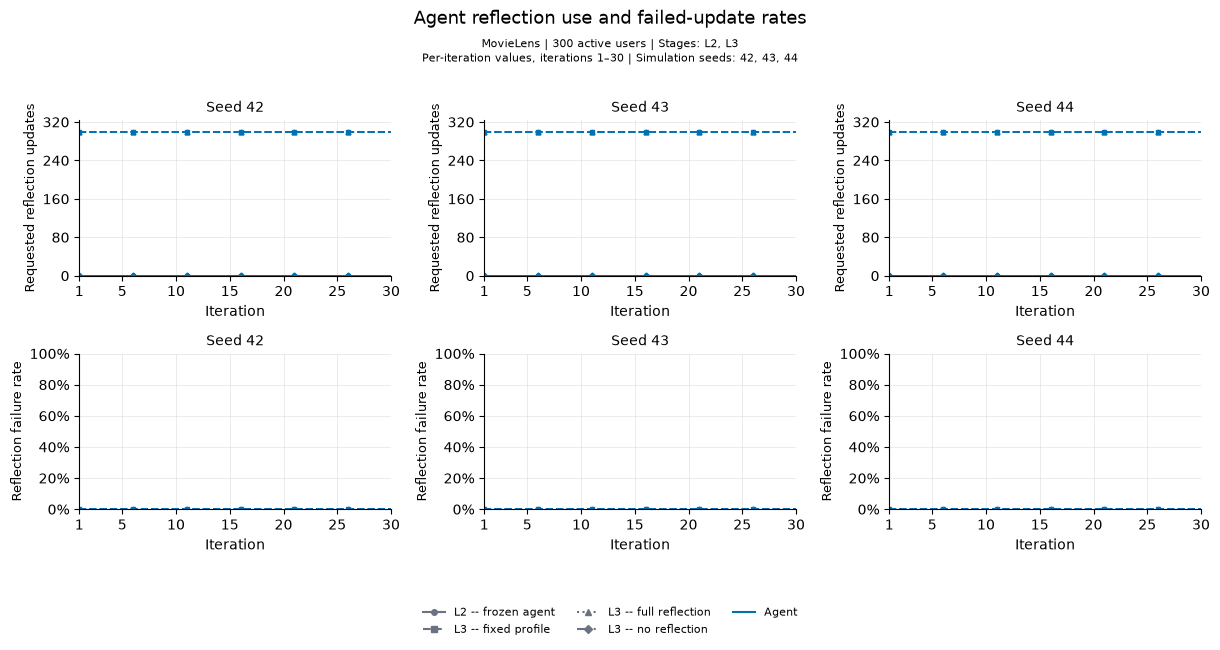

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_reflection_diagnostics.pdf) · [PNG](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_reflection_diagnostics.png) · label `chap:results:fig:rq3_reflection_diagnostics`

In [8]:
report.table(reflection_totals(agent_diagnostics), 'rq3_reflection_totals', "")
diagnostic_tables(report, agent_diagnostics, {'reflection': ['reflection_requested', 'reflection_applied', 'reflection_failed'], 'reflection_failure': ['reflection_error_rate']}, prefix='rq3_agents', context="")
figure = trajectory_grid(agent_diagnostics, ['reflection_requested', 'reflection_error_rate'], title='Agent reflection use and failed-update rates', scales=scales, series='condition_label')
report.figure(figure, agent_diagnostics, 'rq3_reflection_diagnostics', "")

## Applied profile changes


,Model,Seed,profile_changes,Condition
0,Agent,42,0,L2 -- frozen agent
1,Agent,42,0,L3 -- fixed profile
2,Agent,42,1190,L3 -- full reflection
3,Agent,42,0,L3 -- no reflection
4,Agent,43,0,L2 -- frozen agent
5,Agent,43,0,L3 -- fixed profile
6,Agent,43,1254,L3 -- full reflection
7,Agent,43,0,L3 -- no reflection
8,Agent,44,0,L2 -- frozen agent
9,Agent,44,0,L3 -- fixed profile


LaTeX label: `chap:results:tab:rq3_profile_change_totals` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_profile_change_totals.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_profile_change_totals.csv)

,Model,Seed,Time summary,Applied profile-change rate,Profile changed users,Applied profile changes,Condition
0,Agent,42,iteration_30,0,0,0,L2 -- frozen agent
1,Agent,42,mean_1_30,0,0,0,L2 -- frozen agent
2,Agent,43,iteration_30,0,0,0,L2 -- frozen agent
3,Agent,43,mean_1_30,0,0,0,L2 -- frozen agent
4,Agent,44,iteration_30,0,0,0,L2 -- frozen agent
5,Agent,44,mean_1_30,0,0,0,L2 -- frozen agent
6,Agent,42,iteration_30,0.07,21,21,L3 -- full reflection
7,Agent,42,mean_1_30,0.132222,39.6667,39.6667,L3 -- full reflection
8,Agent,43,iteration_30,0.0666667,20,20,L3 -- full reflection
9,Agent,43,mean_1_30,0.139333,41.8,41.8,L3 -- full reflection


LaTeX label: `chap:results:tab:rq3_agents_profile_changes` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_profile_changes.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_profile_changes.csv)

,Model,Seed,Time summary,Users with at least one applied profile change,Condition
0,Agent,42,iteration_30,0,L2 -- frozen agent
1,Agent,42,mean_1_30,0,L2 -- frozen agent
2,Agent,43,iteration_30,0,L2 -- frozen agent
3,Agent,43,mean_1_30,0,L2 -- frozen agent
4,Agent,44,iteration_30,0,L2 -- frozen agent
5,Agent,44,mean_1_30,0,L2 -- frozen agent
6,Agent,42,iteration_30,267,L3 -- full reflection
7,Agent,42,mean_1_30,240.733,L3 -- full reflection
8,Agent,43,iteration_30,268,L3 -- full reflection
9,Agent,43,mean_1_30,240.367,L3 -- full reflection


LaTeX label: `chap:results:tab:rq3_agents_distinct_changed_users` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_distinct_changed_users.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_agents_distinct_changed_users.csv)

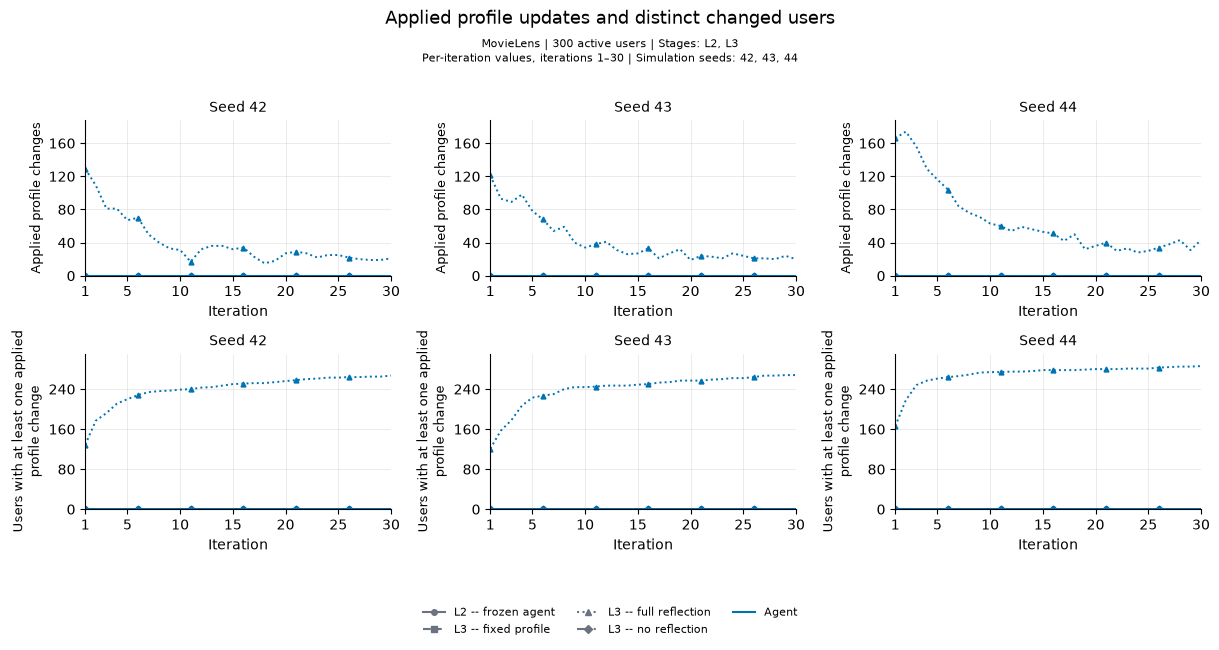

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_profile_updates.pdf) · [PNG](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq3_profile_updates.png) · label `chap:results:fig:rq3_profile_updates`

In [9]:
report.table(horizon_counts(agent_diagnostics, ['profile_changes']), 'rq3_profile_change_totals', "")
diagnostic_tables(report, agent_diagnostics, {'profile_changes': ['profile_changes', 'profile_change_rate', 'profile_changed_users'], 'distinct_changed_users': ['cumulative_profile_changed_users']}, prefix='rq3_agents', context="")
figure = trajectory_grid(agent_diagnostics, ['profile_changes', 'cumulative_profile_changed_users'], title='Applied profile updates and distinct changed users', scales=scales, series='condition_label')
report.figure(figure, agent_diagnostics, 'rq3_profile_updates', "")

## Seeded qualitative profile review


In [10]:
review = results['qualitative_review']
report.table(review, 'rq3_profile_review_selection', "", columns=['seed', 'population_seed', 'user_id', 'review_order', 'eligible_users', 'applied_change_count', 'first_change_iteration', 'last_change_iteration', 'manual_assessment'])
profile_review_details(report, review, results['profile_changes'])

,seed,population_seed,user_id,review_order,eligible_users,applied_change_count,first_change_iteration,last_change_iteration,manual_assessment
0,42,1054,reader_0e7d3e47d179,1,267,4,4,26,Not yet reviewed
1,42,1054,reader_3b7c38d777a7,2,267,2,3,21,Not yet reviewed
2,42,1054,reader_62026194a8e8,3,267,1,17,17,Not yet reviewed
3,42,1054,reader_1f28c8670fb2,4,267,1,1,1,Not yet reviewed
4,42,1054,reader_9e252ba516c9,5,267,2,1,16,Not yet reviewed
5,42,1054,reader_4c782415b6d4,6,267,17,2,30,Not yet reviewed
6,42,1054,reader_6f5a30303a57,7,267,2,4,6,Not yet reviewed
7,42,1054,reader_5e0499cd1ffe,8,267,6,1,30,Not yet reviewed
8,42,1054,reader_0a3f0bf548e3,9,267,10,1,20,Not yet reviewed
9,42,1054,reader_b1be94fc7a70,10,267,7,2,27,Not yet reviewed


LaTeX label: `chap:results:tab:rq3_profile_review_selection` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_profile_review_selection.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_profile_review_selection.csv)

,case_id,seed,review_order,applied_change_count,review_status,extent_of_change,support_in_available_evidence
0,seed42_case01,42,1,4,In progress,minor adjustment,supported
1,seed42_case02,42,2,2,In progress,minor adjustment,mixed
2,seed42_case03,42,3,1,In progress,minor adjustment,unsupported
3,seed42_case04,42,4,1,In progress,minor adjustment,supported
4,seed42_case05,42,5,2,In progress,minor adjustment,supported
5,seed42_case06,42,6,17,In progress,minor adjustment,supported
6,seed42_case07,42,7,2,In progress,minor adjustment,mixed
7,seed42_case08,42,8,6,In progress,minor adjustment,supported
8,seed42_case09,42,9,10,In progress,substantial change,supported
9,seed42_case10,42,10,7,In progress,minor adjustment,supported


LaTeX label: `chap:results:tab:rq3_profile_review_saved_categories` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_profile_review_saved_categories.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_profile_review_saved_categories.csv)

## Descriptive mean and consistency across available seeds


In [11]:
from reported_runs.analysis.presentation import cross_seed_table
for metric in ['head_click_share', 'weighted_head_exposure']:
    table = label_ablation_comparisons(cross_seed_table(results, 'rq3', [metric]), include_order=False)
    report.table(table, f'rq3_seed_consistency_{metric}', "")

,dataset,comparison,model,metric,window,n_seed_blocks,mean_effect,min_effect,max_effect,positive,negative,zero,missing_seeds,effect_unit
0,movielens,Decision-input noise check: no reflection minu...,agentic_recommender,head_click_share,mean_1_30,3,0.751009,-3.92734,4.47714,2,1,0,,percentage points
1,movielens,Decision-input noise check: no reflection minu...,agentic_recommender,head_click_share,iteration_30,3,-7.11226,-19.0325,3.90071,1,2,0,,percentage points
2,movielens,Reflection notes: fixed profile minus no refle...,agentic_recommender,head_click_share,mean_1_30,3,-4.49784,-7.53558,-0.0732353,0,3,0,,percentage points
3,movielens,Reflection notes: fixed profile minus no refle...,agentic_recommender,head_click_share,iteration_30,3,2.66849,-10.1239,15.537,2,1,0,,percentage points
4,movielens,Profile updates: full reflection minus fixed p...,agentic_recommender,head_click_share,mean_1_30,3,-0.336885,-3.46881,2.835,1,2,0,,percentage points
5,movielens,Profile updates: full reflection minus fixed p...,agentic_recommender,head_click_share,iteration_30,3,-3.73907,-9.21833,1.02309,1,2,0,,percentage points


LaTeX label: `chap:results:tab:rq3_seed_consistency_head_click_share` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_seed_consistency_head_click_share.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_seed_consistency_head_click_share.csv)

,dataset,comparison,model,metric,window,n_seed_blocks,mean_effect,min_effect,max_effect,positive,negative,zero,missing_seeds,effect_unit
0,movielens,Decision-input noise check: no reflection minu...,agentic_recommender,weighted_head_exposure,mean_1_30,3,1.83037,-3.06531,7.22064,2,1,0,,percentage points
1,movielens,Decision-input noise check: no reflection minu...,agentic_recommender,weighted_head_exposure,iteration_30,3,0.622959,-3.09533,6.90729,1,2,0,,percentage points
2,movielens,Reflection notes: fixed profile minus no refle...,agentic_recommender,weighted_head_exposure,mean_1_30,3,-3.21864,-6.6214,1.98599,1,2,0,,percentage points
3,movielens,Reflection notes: fixed profile minus no refle...,agentic_recommender,weighted_head_exposure,iteration_30,3,0.810237,-5.43967,7.42811,2,1,0,,percentage points
4,movielens,Profile updates: full reflection minus fixed p...,agentic_recommender,weighted_head_exposure,mean_1_30,3,0.298448,-2.07418,3.07511,1,2,0,,percentage points
5,movielens,Profile updates: full reflection minus fixed p...,agentic_recommender,weighted_head_exposure,iteration_30,3,-1.23269,-2.78909,1.57695,1,2,0,,percentage points


LaTeX label: `chap:results:tab:rq3_seed_consistency_weighted_head_exposure` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_seed_consistency_weighted_head_exposure.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq3_seed_consistency_weighted_head_exposure.csv)